## Análisis de clústeres

In [1]:
from funktionen import *
import pandas as pd
import matplotlib
import numpy as np
import scipy as sp
import math
from scipy import stats
from biofes import biplot
from sklearn.utils.extmath import randomized_svd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn import metrics
from sklearn.metrics import pairwise_distances
import seaborn as sns
sns.set(style="white") #"whitegrid"
%pylab inline

Populating the interactive namespace from numpy and matplotlib


#### Importar datos

In [2]:
data = pd.read_pickle('Data_final')

In [3]:
cols_estrategias = [col for col in data.columns if 'Pct_Uso_' in col]

### Análisis de clústeres basado en las estrategias indicadas

#### Número de clústeres adecuado

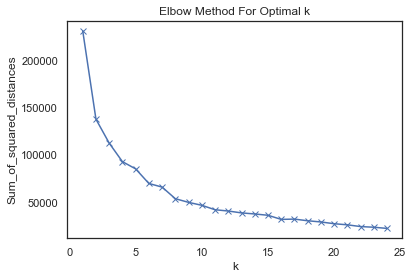

In [4]:
elbow_method(data[cols_estrategias])

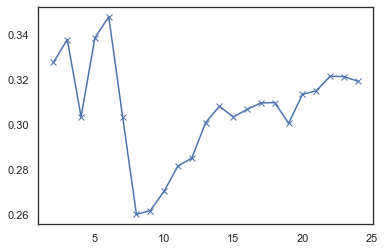

In [5]:
silhouette(data[cols_estrategias])

Los tests indican un número adecuado de 6 clústeres. 

#### Agglomerative Clustering (Agrupamiento aglomerativo)

In [72]:
CL = AgglomerativeClustering(n_clusters=6).fit(data[cols_estrategias])
CL.labels_ = CL.labels_+1

In [73]:
for i in range(1,7):
    print('Cluster '+str(i)+': '+str(data[cols_estrategias].loc[CL.labels_ == i].shape[0]))

Cluster 1: 52
Cluster 2: 48
Cluster 3: 11
Cluster 4: 16
Cluster 5: 10
Cluster 6: 3


Estrategias usadas (a elegir, selección múltiple):
- SQ001: Usar mis conocimientos de otros idiomas (lengua materna u otras lenguas extranjeras)
- SQ002: Analizar la forma de la palabra o sus partes
- SQ003: Sacar conclusiones del contexto inmediato (p.ej. relación con otras palabras en la frase)
- SQ004: Sacar conclusiones del contexto general (p.ej. tema del texto o de la clase)
- SQ005: Fijarme en elementos no verbales (p.ej. imágenes, el formato del texto)
- SQ006: Consultar un diccionario o un traductor online
- SQ007: Usar una aplicación de Inteligencia Artificial (p.ej. Chat GPT)
- SQ008: Preguntar a un/a compañero/a
- SQ009: Preguntar al/a la docente

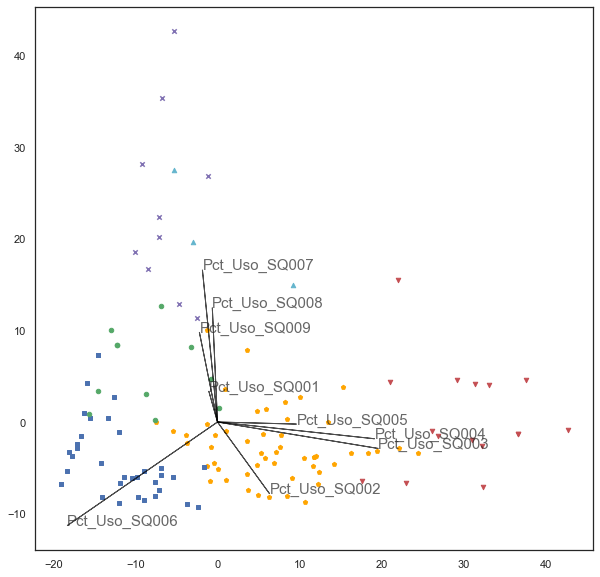

In [74]:
graf_cplot(data[cols_estrategias],8,6)

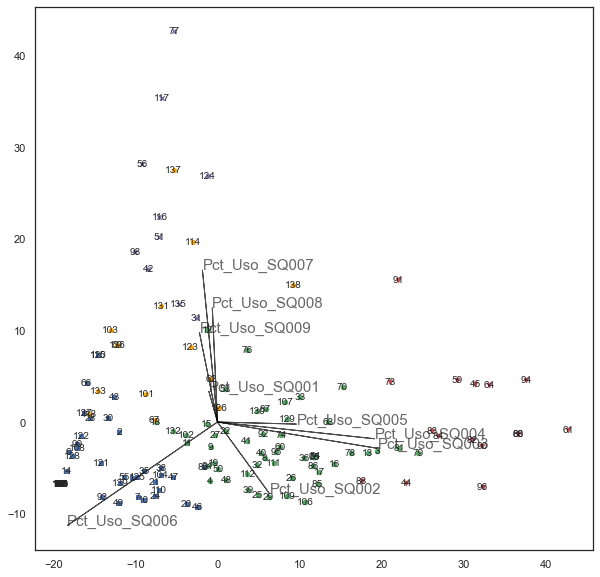

In [75]:
graf_cplot_text(data[cols_estrategias],8,5)

In [76]:
data[cols_estrategias].loc[CL.labels_ == 1] #gelbes Pentagon

,Pct_Uso_SQ001,Pct_Uso_SQ002,Pct_Uso_SQ003,Pct_Uso_SQ004,Pct_Uso_SQ005,Pct_Uso_SQ006,Pct_Uso_SQ007,Pct_Uso_SQ008,Pct_Uso_SQ009
3,4.35,8.70,30.43,26.09,0.00,30.43,0.00,0.00,0.00
4,0.00,8.33,25.00,0.00,0.00,66.67,0.00,0.00,0.00
8,7.69,17.95,28.21,0.00,0.00,43.59,2.56,0.00,0.00
9,11.76,5.88,5.88,17.65,0.00,58.82,0.00,0.00,0.00
11,0.00,0.00,17.65,5.88,0.00,70.59,0.00,5.88,0.00
12,12.50,12.50,0.00,12.50,0.00,37.50,0.00,25.00,0.00
13,11.43,22.86,22.86,14.29,5.71,22.86,0.00,0.00,0.00
15,21.74,4.35,13.04,8.70,0.00,52.17,0.00,0.00,0.00
16,9.43,24.53,24.53,5.66,5.66,30.19,0.00,0.00,0.00
17,0.00,12.50,18.75,25.00,0.00,43.75,0.00,0.00,0.00


Cluster 1: Combinación de diferentes estrategias - mínimo 3 tipos diferentes de los cuales uno es el uso del diccionario/traductor

In [77]:
data[cols_estrategias].loc[CL.labels_ == 2] #blaues Kästchen

,Pct_Uso_SQ001,Pct_Uso_SQ002,Pct_Uso_SQ003,Pct_Uso_SQ004,Pct_Uso_SQ005,Pct_Uso_SQ006,Pct_Uso_SQ007,Pct_Uso_SQ008,Pct_Uso_SQ009
0,0.00,0.00,0.00,0.00,0.0,100.00,0.00,0.00,0.00
1,0.00,0.00,14.29,0.00,0.0,85.71,0.00,0.00,0.00
2,0.00,0.00,0.00,9.09,0.0,81.82,0.00,9.09,0.00
5,0.00,0.00,0.00,0.00,0.0,100.00,0.00,0.00,0.00
6,0.00,0.00,0.00,0.00,0.0,92.86,7.14,0.00,0.00
7,4.17,25.00,0.00,0.00,0.0,70.83,0.00,0.00,0.00
10,0.00,20.00,5.00,0.00,0.0,75.00,0.00,0.00,0.00
14,5.56,0.00,0.00,0.00,0.0,94.44,0.00,0.00,0.00
20,0.00,27.27,0.00,9.09,0.0,63.64,0.00,0.00,0.00
21,0.00,5.26,15.79,0.00,0.0,78.95,0.00,0.00,0.00


Cluster 2: Preferencia para el uso del diccionario/traductor - del 60% de las estrategias usadas hasta el 100%

In [78]:
data[cols_estrategias].loc[CL.labels_ == 3] #grüner Punkt

,Pct_Uso_SQ001,Pct_Uso_SQ002,Pct_Uso_SQ003,Pct_Uso_SQ004,Pct_Uso_SQ005,Pct_Uso_SQ006,Pct_Uso_SQ007,Pct_Uso_SQ008,Pct_Uso_SQ009
62,0.00,0.00,11.11,11.11,0.0,44.44,0.0,0.00,33.33
67,0.00,0.00,0.00,0.00,10.0,70.00,0.0,0.00,20.00
69,0.00,0.00,0.00,0.00,0.0,50.00,0.0,0.00,50.00
101,0.00,0.00,0.00,10.00,0.0,60.00,0.0,0.00,30.00
103,0.00,0.00,0.00,0.00,0.0,58.33,0.0,16.67,25.00
118,0.00,0.00,0.00,0.00,0.0,75.00,0.0,0.00,25.00
123,0.00,0.00,7.69,7.69,0.0,38.46,0.0,0.00,46.15
126,11.11,22.22,0.00,11.11,0.0,33.33,0.0,0.00,22.22
131,8.33,0.00,8.33,0.00,0.0,41.67,0.0,16.67,25.00
133,0.00,0.00,0.00,0.00,0.0,66.67,0.0,0.00,33.33


Cluster 3: Combinan la estrategia de "Preguntar al/a la docente" con el uso del diccionario/traductor (y en parte con otras) 

In [79]:
data[cols_estrategias].loc[CL.labels_ == 4] #rotes Dreieck

,Pct_Uso_SQ001,Pct_Uso_SQ002,Pct_Uso_SQ003,Pct_Uso_SQ004,Pct_Uso_SQ005,Pct_Uso_SQ006,Pct_Uso_SQ007,Pct_Uso_SQ008,Pct_Uso_SQ009
44,4.35,34.78,39.13,8.70,0.00,13.04,0.00,0.00,0.0
45,5.00,5.00,15.00,25.00,25.00,15.00,5.00,5.00,0.0
59,0.00,0.00,37.50,37.50,0.00,12.50,0.00,12.50,0.0
61,0.00,0.00,50.00,50.00,0.00,0.00,0.00,0.00,0.0
64,0.00,0.00,40.00,40.00,0.00,0.00,0.00,0.00,20.0
68,0.00,0.00,33.33,33.33,16.67,16.67,0.00,0.00,0.0
73,0.00,10.00,10.00,30.00,10.00,20.00,0.00,10.00,10.0
80,0.00,0.00,33.33,33.33,16.67,16.67,0.00,0.00,0.0
82,0.00,0.00,36.84,36.84,5.26,21.05,0.00,0.00,0.0
83,0.00,12.50,43.75,12.50,6.25,18.75,0.00,6.25,0.0


Cluster 4: Se basan sobre todo en el contexto para deducir el significado de palabras desconocidas.

In [80]:
data[cols_estrategias].loc[CL.labels_ == 5] #lila Kreuz

,Pct_Uso_SQ001,Pct_Uso_SQ002,Pct_Uso_SQ003,Pct_Uso_SQ004,Pct_Uso_SQ005,Pct_Uso_SQ006,Pct_Uso_SQ007,Pct_Uso_SQ008,Pct_Uso_SQ009
31,11.90,9.52,7.14,4.76,0.0,35.71,30.95,0.00,0.00
42,0.00,0.00,0.00,6.67,0.0,46.67,46.67,0.00,0.00
51,0.00,0.00,0.00,7.14,0.0,42.86,21.43,28.57,0.00
56,0.00,0.00,0.00,0.00,0.0,33.33,33.33,33.33,0.00
77,0.00,0.00,0.00,0.00,0.0,0.00,100.00,0.00,0.00
98,33.33,0.00,0.00,0.00,0.0,33.33,33.33,0.00,0.00
116,0.00,0.00,5.00,0.00,0.0,35.00,10.00,35.00,15.00
117,0.00,0.00,0.00,0.00,0.0,16.67,33.33,41.67,8.33
124,12.50,0.00,12.50,0.00,0.0,12.50,56.25,0.00,6.25
135,25.00,0.00,12.50,0.00,0.0,37.50,25.00,0.00,0.00


Cluster 5: Uso de la IA

In [81]:
data[cols_estrategias].loc[CL.labels_ == 6] #blaues Dreieck

,Pct_Uso_SQ001,Pct_Uso_SQ002,Pct_Uso_SQ003,Pct_Uso_SQ004,Pct_Uso_SQ005,Pct_Uso_SQ006,Pct_Uso_SQ007,Pct_Uso_SQ008,Pct_Uso_SQ009
114,0.00,0.0,7.14,0.0,0.0,7.14,0.0,0.0,85.71
137,0.00,0.0,0.00,0.0,0.0,0.00,20.0,0.0,80.00
138,18.75,0.0,31.25,0.0,0.0,0.00,0.0,0.0,50.00


Cluster 6: Preferencia por preguntar al/a la docente, (casi) no usan el diccionario

In [82]:
data["Cluster"] = CL.labels_

In [83]:
data['Cluster'] = data['Cluster'].replace({1:'Combi',
                                                    2:'Dicc/Trad',
                                                    3:'Prof+Dicc',
                                                    4:'Contexto',
                                                    5:'IA',
                                                      6:'Prof'})

In [84]:
data["Cluster"].value_counts()

Cluster
Combi        52
Dicc/Trad    48
Contexto     16
Prof+Dicc    11
IA           10
Prof          3
Name: count, dtype: int64

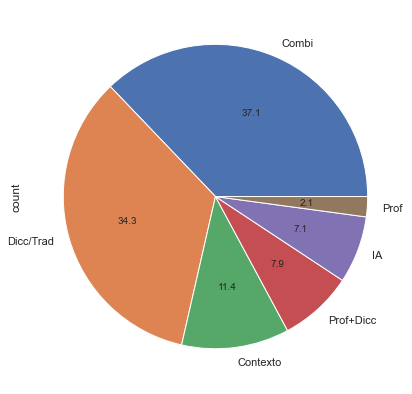

In [85]:
data["Cluster"].value_counts().plot(kind = 'pie',figsize = (7,7), autopct='%.1f');

In [101]:
tabla_counts1 = pd.crosstab(data["Cluster"], data["Idioma"])

orden1 = ['Combi','Dicc/Trad','Contexto','Prof+Dicc','IA','Prof']

tabla_counts1 = tabla_counts1.reindex(orden1)
tabla_counts1

Idioma,Alemán,Chino,Ruso
Cluster,,,
Combi,28,21,3
Dicc/Trad,23,15,10
Contexto,2,14,0
Prof+Dicc,0,5,6
IA,4,2,4
Prof,0,0,3


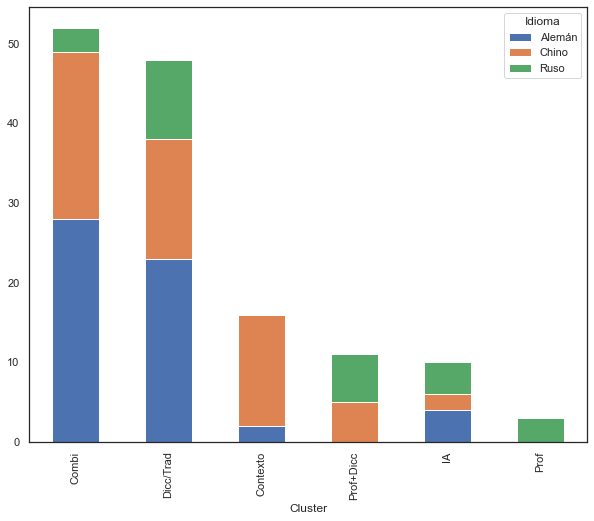

In [105]:
tabla_counts1.plot(kind='bar', figsize = (10,8), stacked = True);

In [102]:
tabla_counts2 = pd.crosstab(data["Cluster"], data["Nivel"])
tabla_counts2 = tabla_counts2.reindex(orden1)
tabla_counts2

Nivel,Intermedio,Principiantes
Cluster,,
Combi,21,31
Dicc/Trad,21,27
Contexto,3,13
Prof+Dicc,6,5
IA,5,5
Prof,2,1


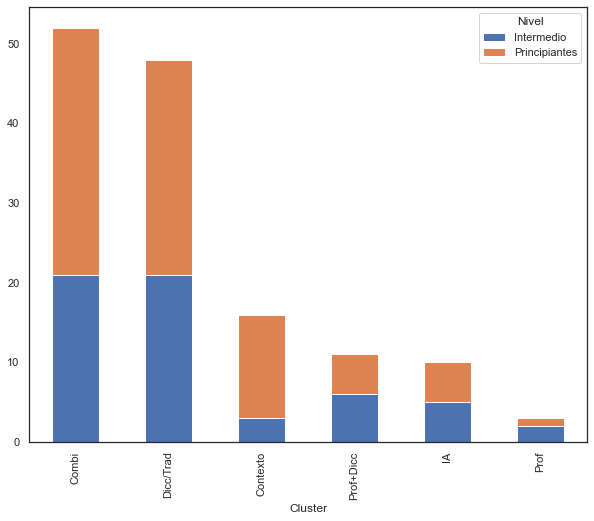

In [103]:
tabla_counts2.plot(kind='bar', figsize = (10,8), stacked = True);